In [1]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
%matplotlib inline

plt.rcParams["font.family"] = "Arial"

import seaborn as sns
from scipy.stats import pearsonr

import matplotlib.colors as mcolors
import matplotlib.transforms as mtransforms

import ast

from additives_microbiota.plotting import process_string, process_string_pretty_vars, ecode_category_colors, get_ecode_category
del ecode_category_colors['unknown']

In [2]:
path_to_additive_name_mapping = "../../data/additive_name_mapping_v3.csv"

## Df food

In [3]:
df_food = pd.read_pickle("../../data/df_food_filtered.pkl")

# df_food = df_food.merge(off_df[["barcode", "additives_tags"]], on="barcode", how="left")

df_food = df_food[(df_food["eaten_quantity_in_gram"] >= 0)]

print(df_food.shape)

(399319, 94)


### Food Categories Selected

In [4]:
food_categories = [
    "carbonated_soft_drinks",
    "energy_drinks",
    "juices_syrups",
    "tea_and_coffee_beverages",
    "milk_and_dairy_alternatives",
    "yogurts",
    "cheese",
    "breakfast_cereals",
    "sweet_bakery",
    "savory_bakery_and_crackers",
    "chocolates_candies_sweets",
    "savory_snacks",
    "nuts_and_seeds",
    "spreads_and_dips",
    "sauces_and_condiments",
    "ready_to_eat_meals",
    "frozen_desserts_and_ice_cream",
    "alcoholic_beverages",
    "meat_and_seafood",
    "fruits_and_vegetables",
    "vegan_alternatives",
    "pasta_and_noodles",
    "others",
]

In [5]:
off_df = pd.read_pickle("../../data/df_food_openfoodfacts_merged.pkl")

print(off_df.shape)

off_df.head()

(12710, 46)


,product_name,generic_name,quantity,brands,brands_tags,countries,stores,categories,food_groups,ingredients_text,...,carbohydrates_100g,sugars_100g,fat_100g,saturated-fat_100g,fiber_100g,salt_100g,sodium_100g,calcium_100g,iron_100g,nutrition-score-fr_100g
1000,Thé vert menthe,NaN,0.5l,"Naturaplan,Coop","['naturaplan', 'coop']","['en:france', 'en:germany', 'en:switzerland']",['coop'],"['en:beverages-and-beverages-preparations', 'e...","['en:beverages', 'en:sweetened-beverages']","Eau, sucre de canne brut (Paraguay), jus de ci...",...,5.0,5.0,0.0,0.0,0.0,0.000,0.000,NaN,NaN,5.0
1001,Sushi Ingwer,Gingembre avec édulcorant,NaN,OLUF LORENTZEN AS,['oluf-lorentzen-as'],"['en:belgium', 'en:france', 'en:germany', 'en:...","['carrefour-city', 'delhaize']","['en:plant-based-foods-and-beverages', 'en:pla...",[],"Gingembre 58 %, eau, sel, acidifiants : acide ...",...,1.3,0.0,0.0,0.0,NaN,2.000,0.800,NaN,NaN,NaN
1002,Energy milk,NaN,NaN,Emmi,['emmi'],"['en:france', 'en:switzerland']",['coop'],"['en:dairies', 'en:desserts', 'en:dairy-desser...","['en:milk-and-dairy-products', 'en:dairy-desse...","Lait suisse partiellement écrémé avec 1,5% de ...",...,4.6,4.4,1.5,0.9,NaN,0.285,0.114,NaN,NaN,-2.0
1003,Sambal Oelek,NaN,100 g,Mei Yang,['mei-yang'],"['en:france', 'en:switzerland']",[],"['en:condiments', 'en:sauces', 'en:hot-sauces']","['en:fats-and-sauces', 'en:dressings-and-sauces']","piments rouges 86%, sel, acidifiant: acide acé...",...,3.2,2.8,1.2,0.2,NaN,12.500,5.000,NaN,NaN,15.0
1004,Cottage Cheese sans lactose,NaN,150 g,Coop,['coop'],"['en:france', 'en:switzerland']",[],"['en:dairies', 'en:fermented-foods', 'en:ferme...","['en:salty-snacks', 'en:salty-and-fatty-produc...","Lait écrémé, crème sans lactose, sel de cuisin...",...,3.5,3.5,4.5,3.0,0.0,0.800,0.320,NaN,NaN,2.0


## 2. Load Previous Additive Containing Foods

In [6]:
additive_barcodes = pd.read_csv(
    "../../data/unique_barcodes_with_additives.csv", dtype={"barcode": str}
)
print("total unique additive barcodes: ", len(additive_barcodes))

additive_barcodes.head()

total unique additive barcodes:  4119


,barcode
0,0014100096986
1,0014100096993
2,0016000502666
3,0016229901141
4,0022000159342


## Assigning food groups to Food Dataframe

In [7]:
additive_foods = df_food.merge(
    off_df[["barcode", "additives_tags"]], on="barcode", how="left"
)

additive_foods["additives_tags"] = additive_foods["additives_tags"].apply(
    lambda x: (
        ast.literal_eval(x) if isinstance(x, str) else x if isinstance(x, list) else []
    )
)

additive_foods = additive_foods[
    (additive_foods["additives_tags"].apply(lambda x: len(x) > 0))
]

additive_foods["additives_tags"] = additive_foods["additives_tags"].map(
    lambda x: [i.replace("en:", "") for i in x]
)


def map_food_group(barcode):
    # ## Read the barcoded foods annotated file. This makes it very slow, but required for testing.
    barcoded_foods_annotated = pd.read_csv(
        "../../data/additive_analysis_files/additive_foods_group_annotations.csv",
        index_col=0,
        dtype={"barcode": str},
    )

    if barcode in barcoded_foods_annotated["barcode"].values:
        return barcoded_foods_annotated[barcoded_foods_annotated["barcode"] == barcode][
            "food_group"
        ].values[0]
    else:
        return "unknown"


additive_foods["food_group"] = additive_foods["barcode"].map(map_food_group)

additive_foods.shape

(16324, 96)

In [8]:
additive_foods[additive_foods["food_group"] == "unknown"][
    "combined_name"
].value_counts()

Series([], Name: count, dtype: int64)

In [9]:
print(additive_foods[additive_foods["food_group"] == "others"]["barcode"].nunique())

additive_foods[additive_foods["food_group"] == "others"][
    "combined_name"
].value_counts()[:]

42


combined_name
Xylit : Süssungsmittel aus Birke und Buche                                  22
unknown                                                                     15
PowerBar - 30% PROTEIN PLUS (Chocolat)                                      11
Original Le Parfait                                                         11
Scitec nutrition - 100% plant protein                                        8
ORIGINAL le Parfait                                                          7
Waterdrop - Microdrink, ZEN (star fruit, lemon grass, white tea flavour)     7
Crane - Whey Protein                                                         6
Myprotein - Flavdrops (cheesecake flavour)                                   6
Sponser - Multi protein (vanilla flavor)                                     6
MBudget - Whey Proteinpulver (Vanillearoma)                                  6
Wasa Gluten And Lactose Free                                                 6
ON Optimum nutrition - Gold Standard W

In [10]:
additive_foods["food_group"].value_counts()

food_group
chocolates_candies_sweets        2967
sweet_bakery                     2069
carbonated_soft_drinks           1408
savory_bakery_and_crackers       1342
sauces_and_condiments             897
ready_to_eat_meals                716
milk_and_dairy_alternatives       699
savory_snacks                     593
yogurts                           567
tea_and_coffee_beverages          526
meat_and_seafood                  507
spreads_and_dips                  491
frozen_desserts_and_ice_cream     488
cheese                            475
juices_syrups                     459
vegan_alternatives                390
fruits_and_vegetables             359
breakfast_cereals                 358
energy_drinks                     305
nuts_and_seeds                    254
alcoholic_beverages               214
others                            155
pasta_and_noodles                  85
Name: count, dtype: int64

## One-hot encoding to get the count of each additive across all logged foods

In [11]:
# # 2) explode and get dummies, then reindex to fill missing rows with 0
# temp = additive_foods["additives_tags"].explode().to_frame("code")
# dummies = pd.get_dummies(temp["code"])
# dummies = dummies.groupby(level=0).max().reindex(df_food.index, fill_value=0)

# # 3) join the one‑hot columns back on and drop the helper
# additive_foods = additive_foods.join(dummies)
# additive_foods.drop(columns="additives_tags", inplace=True)

In [12]:
temp = additive_foods["additives_tags"].explode().to_frame("code")

dummies = (
    pd.get_dummies(temp["code"])
    .groupby(level=0)
    .max()
    .reindex(additive_foods.index, fill_value=0)
)

additive_foods = additive_foods.join(dummies)
additive_foods.drop(columns="additives_tags", inplace=True)

In [13]:
# Save unique product names to a test file
unique_names = additive_foods["combined_name"].unique()
np.savetxt("../../data/unique_product_names.txt", unique_names, fmt="%s")
unique_names

array(['Dar Vida - UrDinkel', 'Viennetta Vanilla', 'Coca-Cola', ...,
       'Patissier Candied cherries',
       'M-Budget Table water with lemon aroma',
       'alpro - Joghurt (Heidelbeere)'], shape=(3717,), dtype=object)

## Additive Category Mapping

In [14]:
additive_type_mapping = pd.read_csv(path_to_additive_name_mapping)

additive_type_mapping["category"] = additive_type_mapping["ecode"].map(
    get_ecode_category
)
additive_type_mapping

,ecode,name,category
0,e100,Curcumin,colorants
1,e101,Riboflavin,colorants
2,e101ii,Riboflavin-5'-phosphate,colorants
3,e102,Tartrazine,colorants
4,e104,Quinoline yellow,colorants
...,...,...,...
389,e341iii,Tricalcium phosphate,ph_regulators_anti_caking_leavening_agents
390,e381,Ammonium ferric citrate,ph_regulators_anti_caking_leavening_agents
391,e165,Gardenia blue (genipin-gardenia),colorants
392,e580,Magnesium lactate,ph_regulators_anti_caking_leavening_agents


In [15]:
# additive_type_mapping.to_csv("../data/additive_name_mapping_v4.csv", index=False)

In [16]:
def get_coexisting_additives_for_food(
    food_group, additive_foods, threshold=10, save_path: str = None
):
    food_df = additive_foods[
        (additive_foods["food_group"] == food_group)
        & (additive_foods["barcode"].notna())
    ]
    df = food_df.drop_duplicates(subset=["barcode"])
    food_group_additives = df[
        [i for i in food_df.columns if i in additive_type_mapping["ecode"].values]
    ]
    coexisting_additives = food_group_additives.sum(axis=0)[
        food_group_additives.sum(axis=0) > threshold
    ].index

    # Get result without triggering FutureWarning about downcasting
    result = food_group_additives[coexisting_additives].copy()
    result = result.infer_objects(copy=False).fillna(False)
    result = result[~(result == False).all(axis=1)]

    # build a tuple of present additives (with "en:" prefix) for each row
    combo_series = result.apply(
        lambda row: tuple("en:" + col for col, present in row.items() if present),
        axis=1,
    )

    # count how many times each combination occurs, sorted descending
    combo_counts = combo_series.value_counts()

    # format as list of dicts
    output = [
        {"additives": list(combo), "count": int(cnt)}
        for combo, cnt in combo_counts.items()
    ]

    if save_path:
        with open(save_path, "w") as fp:
            json.dump(output, fp, indent=2)

    return output

In [17]:
for fc in food_categories:
    get_coexisting_additives_for_food(
        fc,
        additive_foods,
        threshold=0,
        save_path=f"../../data/additive_analysis_files/json/cooccurrence_{fc}.json",
    )

## Analysis

In [18]:
# Apply a small translation to the x-tick labels
def shift_xtick_labels(g, ha="right", x_shift=5):
    """
    Adjust the x-tick labels of a plot.
    """
    for label in g.get_xticklabels():
        label.set_ha(ha)
        offset = mtransforms.ScaledTranslation(
            x_shift / 72, 0, g.figure.dpi_scale_trans
        )  # shift right by x_shift points
        label.set_transform(label.get_transform() + offset)

In [19]:
summed_additives = (
    additive_foods.drop_duplicates("barcode")
    .groupby("food_group")[temp["code"].unique().tolist()]
    .sum()
    .astype(int)
)

summed_additives = summed_additives.reindex(
    summed_additives.sum().sort_values(ascending=False).index, axis=1
)

summed_additives.to_csv(
    "../../data/additive_analysis_files/summed_additives_across_food_categories.csv"
)

summed_additives

,e330,e322,e322i,e500,e471,e300,e14xx,e450,e415,e440,...,e425,e529,e948,e416,e381,e402,e132,e1420,e212,e1202
food_group,,,,,,,,,,,,,,,,,,,,,
alcoholic_beverages,17,2,2,1,1,4,0,1,1,0,...,0,0,0,0,0,0,0,0,0,0
breakfast_cereals,12,46,30,4,2,2,4,1,0,2,...,0,0,0,0,0,0,0,0,0,0
carbonated_soft_drinks,87,0,0,0,0,24,6,0,0,5,...,0,0,1,0,1,0,0,0,1,0
cheese,18,2,2,3,3,2,4,10,14,2,...,0,0,0,0,0,0,0,0,0,0
chocolates_candies_sweets,137,453,332,79,42,5,19,7,2,33,...,0,0,0,0,0,0,0,0,0,0
energy_drinks,34,1,1,6,0,3,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
frozen_desserts_and_ice_cream,18,73,50,21,90,0,6,0,4,19,...,0,0,0,0,0,0,0,0,0,0
fruits_and_vegetables,65,1,1,0,2,45,2,2,7,4,...,0,0,0,0,0,0,0,0,0,0
juices_syrups,63,2,2,1,2,42,1,0,2,14,...,0,0,0,0,0,0,0,0,0,0


In [20]:
summed_additives.sum(axis=1).sort_values(ascending=False)

food_group
chocolates_candies_sweets        2510
sweet_bakery                     2358
ready_to_eat_meals                992
meat_and_seafood                  717
frozen_desserts_and_ice_cream     683
savory_bakery_and_crackers        617
carbonated_soft_drinks            561
sauces_and_condiments             490
milk_and_dairy_alternatives       448
savory_snacks                     420
spreads_and_dips                  384
yogurts                           322
tea_and_coffee_beverages          290
fruits_and_vegetables             241
juices_syrups                     232
breakfast_cereals                 231
pasta_and_noodles                 221
vegan_alternatives                220
cheese                            220
energy_drinks                     200
others                            151
nuts_and_seeds                    120
alcoholic_beverages                93
dtype: int64

In [21]:
summed_additives_categorized = summed_additives.copy()

summed_additives_categorized.columns = summed_additives_categorized.columns.map(
    lambda x: (
        additive_type_mapping[additive_type_mapping["ecode"] == x]["category"].values[0]
        if x in additive_type_mapping["ecode"].values
        else "unknown"
    )
)

# Group by category and sum up the values for each food group
# Using T.groupby instead of groupby with axis=1 to avoid FutureWarning
summed_additives_by_category = summed_additives_categorized.T.groupby(level=0).sum().T
summed_additives_by_category.drop(columns=["unknown"], inplace=True)

summed_additives_by_category.to_csv(
    "../../data/additive_analysis_files/summed_additives_types_across_food_categories.csv"
)

summed_additives_by_category

,colorants,flavor_enhancers,other_additives,ph_regulators_anti_caking_leavening_agents,preservatives_antioxidants,sweeteners_glazing_agents,thickeners_stabilizers_emulsifiers_gelling_agents
food_group,,,,,,,
alcoholic_beverages,18,0,2,48,10,2,9
breakfast_cereals,20,0,0,34,47,31,99
carbonated_soft_drinks,70,0,1,308,52,91,37
cheese,31,7,1,81,38,0,62
chocolates_candies_sweets,265,0,4,497,57,559,1128
energy_drinks,40,1,0,92,17,32,18
frozen_desserts_and_ice_cream,62,0,0,73,0,15,533
fruits_and_vegetables,4,7,2,90,102,7,29
juices_syrups,15,0,0,91,66,19,41


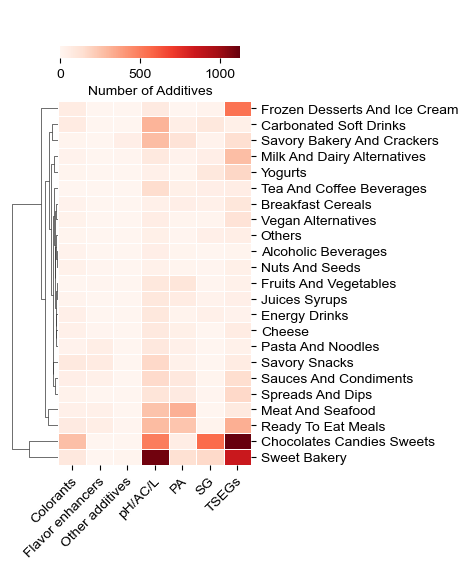

In [22]:
g = sns.clustermap(
    summed_additives_by_category,
    cmap="Reds",
    figsize=(5, 8),
    linewidths=0.5,
    col_cluster=False,
    cbar_pos=(0.13, 0.92, 0.36, 0.015),  # Position colorbar at the top
    cbar_kws={
        "orientation": "horizontal",
        "label": "Number of Additives",
    },
)

g.ax_heatmap.set_ylabel("")  # Remove y-axis label
plt.setp(g.ax_heatmap.get_xticklabels(), rotation=45, ha="right")

# Process x-tick labels (column names)
x_labels = [
    # label.get_text().replace("_", " ").title()
    process_string_pretty_vars(label.get_text())
    for label in g.ax_heatmap.get_xticklabels()
]
g.ax_heatmap.set_xticklabels(x_labels)

# Process y-tick labels (food groups)
y_labels = [
    label.get_text().replace("_", " ").title()
    for label in g.ax_heatmap.get_yticklabels()
]
g.ax_heatmap.set_yticklabels(y_labels)

shift_xtick_labels(g.ax_heatmap)

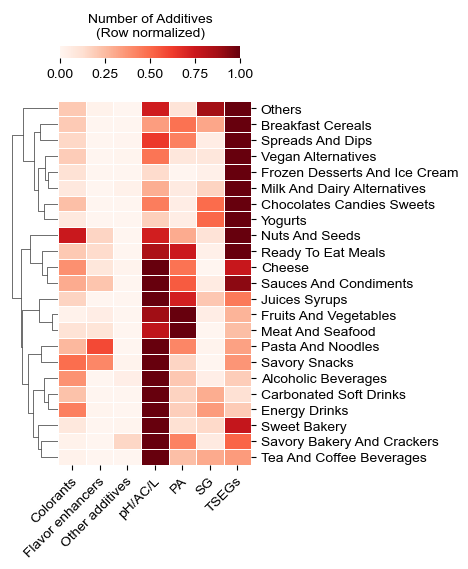

In [23]:
g = sns.clustermap(
    summed_additives_by_category,
    standard_scale=0,
    cmap="Reds",
    figsize=(5, 8),
    linewidths=0.5,
    col_cluster=False,
    cbar_pos=(0.13, 0.92, 0.36, 0.015),  # Position colorbar at the top
    cbar_kws={
        "orientation": "horizontal",
        "label": "Number of Additives\n(Row normalized)",
    },
)

g.ax_heatmap.set_ylabel("")
# Rotate the x-axis tick labels for better readability
plt.setp(g.ax_heatmap.get_xticklabels(), rotation=45, ha="right")

# Process x-tick labels (column names)
x_labels = [
    process_string_pretty_vars(label.get_text())
    for label in g.ax_heatmap.get_xticklabels()
]
g.ax_heatmap.set_xticklabels(x_labels)


# Process y-tick labels (food groups)
y_labels = [
    process_string_pretty_vars(label.get_text())
    for label in g.ax_heatmap.get_yticklabels()
]
g.ax_heatmap.set_yticklabels(y_labels)


# # Apply a small translation to the x-tick labels
# for label in g.ax_heatmap.get_xticklabels():
#     label.set_ha("right")
#     offset = mtransforms.ScaledTranslation(
#         5 / 72, 0, g.ax_heatmap.figure.dpi_scale_trans
#     )  # shift right by 5 points
#     label.set_transform(label.get_transform() + offset)

shift_xtick_labels(g.ax_heatmap)


cbar = g.cax  # g.cax is the colorbar axis in clustermap
cbar.xaxis.set_label_position("top")
cbar.xaxis.label.set_verticalalignment("bottom")  # helps tighten spacing
cbar.xaxis.labelpad = 5  # adjust as needed


plt.savefig(
    "../figures/additive_descriptive/normalized_additive_type_presence_by_food_group.png",
    dpi=300,
    bbox_inches="tight",
)

In [24]:
# plot_data_summed_additives = summed_additives.fillna(0)[
#     summed_additives.sum(axis=0).sort_values(ascending=False)[:50].index
# ]

# plot_data_summed_additives.index = plot_data_summed_additives.index.map(process_string)

# plot_data_summed_additives.columns = plot_data_summed_additives.columns.map(
#     lambda i: i
#     + " - "
#     + additive_type_mapping[additive_type_mapping["ecode"] == i]["name"].values[0]
# )

# # ecode_category_colors = {
# #     "colorants": "gold",
# #     "preservatives_antioxidants": "#66b3ff",
# #     "thickeners_stabilizers_emulsifiers_gelling_agents": "#ffcc99",
# #     "ph_regulators_anti_caking_leavening_agents": "#b3de69",
# #     "flavor_enhancers": "#ffb3e6",
# #     "sweeteners_glazing_agents": "#c2c2f0",
# #     "other_additives": "#c2f0c2",
# #     # "unknown": "#cccccc",
# # }


# # Function to create darker versions of colors
# def darken_color(color, factor=0.9):
#     """Returns a darker version of the given color.
#     Lower factor = darker color (0 to 1 range)
#     """
#     rgb = mcolors.to_rgb(color)
#     darker_rgb = [c * factor for c in rgb]
#     return mcolors.to_hex(darker_rgb)


# # Create darker versions of the category colors
# ecode_category_colors_darker = {
#     category: darken_color(color) for category, color in ecode_category_colors.items()
# }

# # Create a Series that maps each additive to its category color
# # First, we need to extract the category for each row in your plot data
# row_categories = []
# category_map = {}  # To store ecode to category mapping
# for col in plot_data_summed_additives.columns:
#     # Extract the ecode from the column name
#     ecode = col.split(" - ")[0]
#     # Get the category for this ecode
#     category = additive_type_mapping.loc[
#         additive_type_mapping["ecode"] == ecode, "category"
#     ].values[0]
#     row_categories.append(category)
#     # Store the mapping of column name to category
#     category_map[col] = category

# # Create a Series with colors based on categories
# row_colors = pd.Series(
#     [ecode_category_colors[cat] for cat in row_categories],
#     index=plot_data_summed_additives.columns,
# )

# # Create the clustermap with row colors
# g = sns.clustermap(
#     plot_data_summed_additives.T,
#     standard_scale=0,
#     # z_score=0,
#     linewidths=0.1,
#     figsize=(8, 12),
#     cmap="Reds",
#     dendrogram_ratio=0.1,
#     row_colors=row_colors,
#     cbar_kws={
#         "orientation": "horizontal",
#         "label": "Number of Additives\n(Row normalized)",
#     },
#     cbar_pos=(0.1, 0.98, 0.36, 0.015),
# )

# # Remove the x-axis label
# g.ax_heatmap.set_xlabel("Barcoded Food Groups")


# # Color the row labels according to their categories with darker colors
# # Get the row labels from the heatmap
# row_labels = g.ax_heatmap.get_yticklabels()

# # Get the reordered indices from the row dendrogram
# reordered_idx = g.dendrogram_row.reordered_ind

# # Set the color for each row label based on its category
# for i, label in enumerate(row_labels):
#     # Get the original index of this label from the reordered indices
#     original_idx = reordered_idx[i]
#     # Get the original column name (now a row in the transposed data)
#     col_name = plot_data_summed_additives.columns[original_idx]
#     # Get the category for this column
#     category = category_map[col_name]
#     # Set the label color to a darker shade
#     label.set_color(ecode_category_colors_darker[category])
#     # Optional: make the font bold for better visibility
#     label.set_fontweight("bold")

# # Apply the modified labels back to the heatmap
# g.ax_heatmap.set_yticklabels(row_labels)

# shift_xtick_labels(g.ax_heatmap)

# # Hide dendrograms but keep clustering
# g.ax_row_dendrogram.set_visible(False)
# g.ax_col_dendrogram.set_visible(False)

# # Optionally remove the space they occupy
# # g.fig.subplots_adjust(left=0.15, top=0.9)

# # Add a legend for the categories
# handles = [
#     plt.Rectangle((0, 0), 1, 1, color=color) for color in ecode_category_colors.values()
# ]
# plt.legend(
#     handles,
#     [process_string(key) for key in ecode_category_colors.keys()],
#     title="Additive Categories",
#     loc="center left",
#     bbox_to_anchor=(1.2, 0.5),
#     frameon=False,
#     title_fontsize=11,
# )

# # Remove tick marks/labels on the row_colors axis (the colored strip)
# if hasattr(g, "ax_row_colors") and g.ax_row_colors is not None:
#     g.ax_row_colors.set_xticks([])
#     g.ax_row_colors.set_yticks([])
#     g.ax_row_colors.tick_params(
#         left=False, bottom=False, labelleft=False, labelbottom=False
#     )
#     for spine in g.ax_row_colors.spines.values():
#         spine.set_visible(False)


# # plt.savefig(
# #     "../figures/additive_descriptive/normalized_additive_presence_by_food_group.png",
# #     dpi=300,
# #     bbox_inches="tight",
# # )

# plt.show()

 # Additive presence in food group and prevalence across users

In [25]:
additive_user_prevalence_df = pd.read_csv(
    "../../data/additive_analysis_files/additive_prevalence_across_users.csv",
)
additive_user_prevalence_df

,additive,prevalence_counts,prevalence,category
0,e330,777,0.77,ph_regulators_anti_caking_leavening_agents
1,e322,742,0.74,thickeners_stabilizers_emulsifiers_gelling_agents
2,e322i,654,0.65,thickeners_stabilizers_emulsifiers_gelling_agents
3,e500,640,0.63,ph_regulators_anti_caking_leavening_agents
4,e471,516,0.51,thickeners_stabilizers_emulsifiers_gelling_agents
...,...,...,...,...
252,e1202,1,0.00,thickeners_stabilizers_emulsifiers_gelling_agents
253,e948,1,0.00,other_additives
254,e381,1,0.00,ph_regulators_anti_caking_leavening_agents
255,e510,1,0.00,ph_regulators_anti_caking_leavening_agents


### Plotting Counts of Additive Categories

In [26]:
category_counts = (
    additive_user_prevalence_df.reset_index()
    .groupby("category")
    .agg(count=("additive", "count"))
)

pie_order = [
    "thickeners_stabilizers_emulsifiers_gelling_agents",
    "flavor_enhancers",
    "sweeteners_glazing_agents",
    "preservatives_antioxidants",
    "ph_regulators_anti_caking_leavening_agents",
    "other_additives",
    "colorants",
]

category_counts = category_counts.reindex(pie_order)

In [27]:
def plot_additive_category_pie(
    category_counts_df,
    ax=None,
    figsize=(4, 4),
    colors=None,
    startangle=90,
):
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    counts = category_counts_df["count"]
    labels = [process_string_pretty_vars(c) for c in counts.index]
    total = counts.sum()

    def autopct_pct_and_count(pct):
        count = int(round(pct * total / 100.0))
        return f"{pct:.0f}% ({count})" if count > 0 else ""

    pie_kwargs = dict(
        labels=labels,
        autopct=autopct_pct_and_count,
        startangle=startangle,
    )

    if colors is not None:
        pie_kwargs["colors"] = [colors.get(c, None) for c in counts.index]

    wedges, texts, autotexts = ax.pie(counts, **pie_kwargs)

    ax.set_aspect("equal")
    ax.set_title(f"Total additives: {total}", y=0.94)

    for t in texts:
        t.set_fontsize(10)
    for at in autotexts:
        at.set_fontsize(9)

    return ax

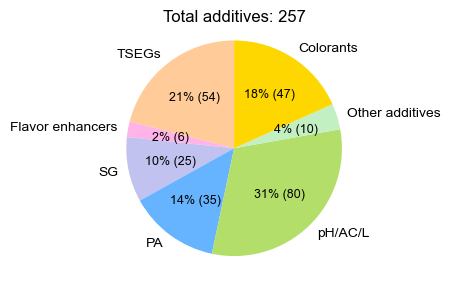

In [28]:
fig, ax = plt.subplots(figsize=(3.5, 3.5))
plot_additive_category_pie(
    category_counts_df=category_counts,
    ax=ax,
    colors=ecode_category_colors,
)

sns.despine(left=True, bottom=True)

plt.savefig(
    "../figures/additive_descriptive/additive_category_counts_pie.png",
    dpi=300,
    bbox_inches="tight",
)

In [29]:
def plot_additive_category_bar(
    category_counts_df,
    ax=None,
    figsize=(6, 3.5),
    colors=None,
):
    """Bar plot analogue of ``plot_additive_category_pie`` (same labels and colors)."""
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    counts = category_counts_df["count"]
    labels = [process_string_pretty_vars(c) for c in counts.index]
    total = int(counts.sum())
    pcts = 100.0 * counts.values / total if total else np.zeros(len(counts))

    if colors is not None:
        bar_colors = [colors.get(c) or "#cccccc" for c in counts.index]
    else:
        bar_colors = None

    y = np.arange(len(counts))
    ax.barh(y, counts.values, color=bar_colors, edgecolor="white", linewidth=0.6)
    ax.set_yticks(y)
    ax.set_yticklabels(labels, fontsize=10)
    ax.invert_yaxis()

    for yi, val, pct in zip(y, counts.values, pcts):
        if val <= 0:
            continue
        label = f"{pct:.0f}% ({int(val)})"
        ax.text(
            val,
            yi,
            f"  {label}",
            va="center",
            ha="left",
            fontsize=9,
        )

    ax.set_xlabel("Count")
    ax.set_title(f"Total additives: {total}", y=1.02)
    xmax = float(np.nanmax(counts.values)) if len(counts) else 0.0
    if xmax > 0:
        ax.set_xlim(0, xmax * 1.42)
    return ax

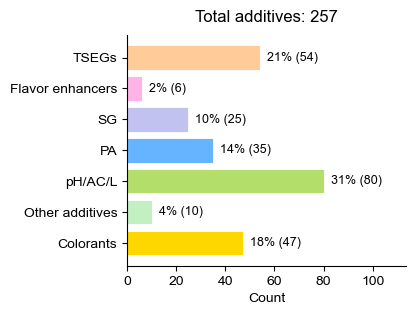

In [30]:
fig, ax = plt.subplots(figsize=(3.6, 3))
plot_additive_category_bar(
    category_counts_df=category_counts,
    ax=ax,
    colors=ecode_category_colors,
)

sns.despine(ax=ax)

plt.savefig(
    "../figures/additive_descriptive/additive_category_counts_bar.png",
    dpi=300,
    bbox_inches="tight",
)

### Heatmap of additive presence by food group and prevalence across users

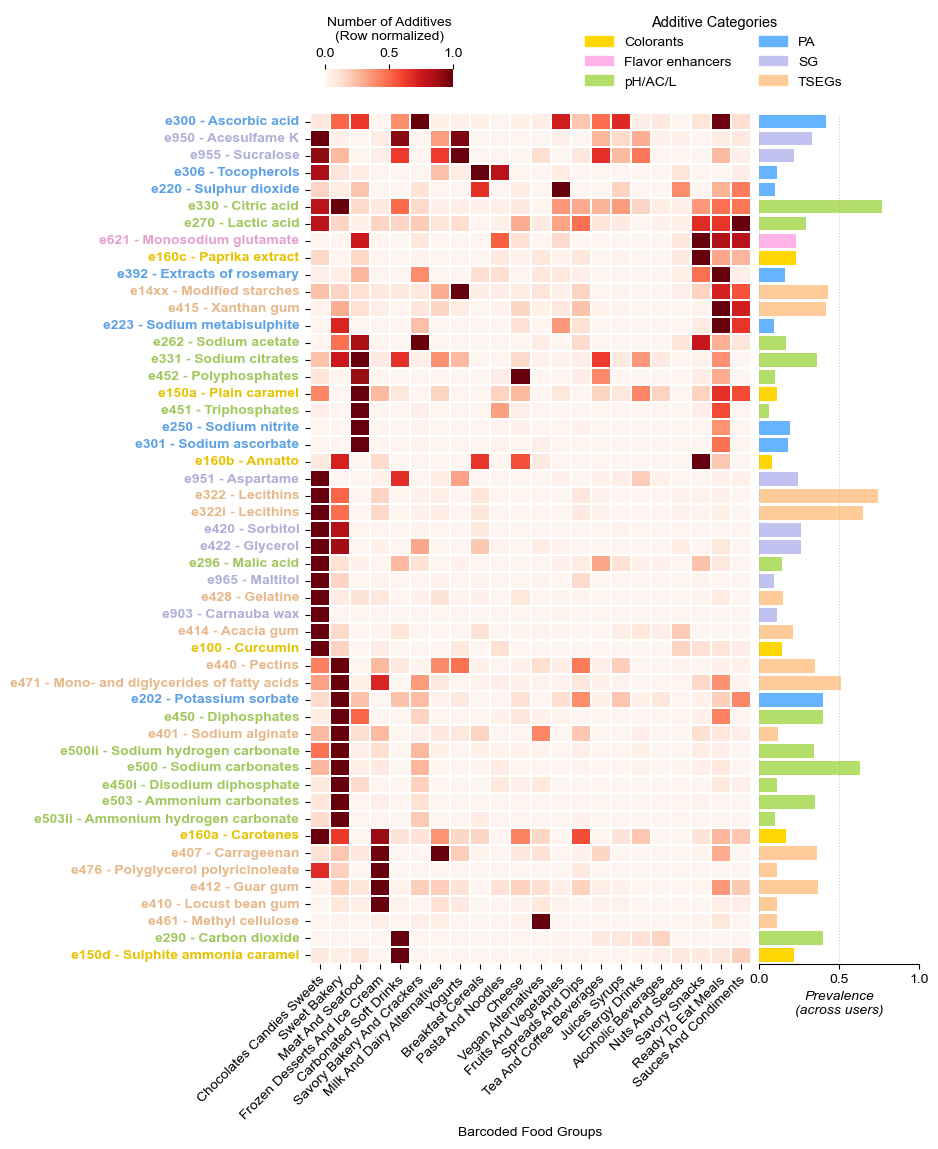

In [32]:
plot_data_summed_additives = summed_additives.fillna(0)[
    summed_additives.sum(axis=0).sort_values(ascending=False)[:50].index
]
plot_data_summed_additives.drop(index=["others"], inplace=True)
plot_data_summed_additives.index = plot_data_summed_additives.index.map(process_string)

plot_data_summed_additives.columns = plot_data_summed_additives.columns.map(
    lambda i: i
    + " - "
    + additive_type_mapping[additive_type_mapping["ecode"] == i]["name"].values[0]
)


def darken_color(color, factor=0.9):
    rgb = mcolors.to_rgb(color)
    darker_rgb = [c * factor for c in rgb]
    return mcolors.to_hex(darker_rgb)


ecode_category_colors_darker = {
    category: darken_color(color) for category, color in ecode_category_colors.items()
}

# Map each additive column (ecode - name) to its category
category_map = {}
for col in plot_data_summed_additives.columns:
    ecode = col.split(" - ")[0]
    category = additive_type_mapping.loc[
        additive_type_mapping["ecode"] == ecode, "category"
    ].values[0]
    category_map[col] = category

# ---- clustermap (no row_colors) ----
g = sns.clustermap(
    plot_data_summed_additives.T,
    standard_scale=0,
    linewidths=0.1,
    figsize=(8, 12),
    cmap="Reds",
    dendrogram_ratio=0.1,
    cbar_kws={
        "orientation": "horizontal",
        "label": "Number of Additives\n(Row normalized)",
    },
    cbar_pos=(0.1, 0.93, 0.16, 0.015),
)

cax = g.cax
cax.xaxis.set_label_position("top")
cax.xaxis.set_ticks_position("top")
cax.xaxis.labelpad = 6

g.ax_heatmap.set_xlabel("Barcoded Food Groups")

g.ax_heatmap.set_xticklabels(g.ax_heatmap.get_xticklabels(), rotation=45)
shift_xtick_labels(g.ax_heatmap)

# Hide dendrograms but keep clustering
g.ax_row_dendrogram.set_visible(False)
g.ax_col_dendrogram.set_visible(False)

# ---- move y tick labels to the left (then re-color them) ----
g.ax_heatmap.yaxis.set_ticks_position("left")
g.ax_heatmap.yaxis.set_label_position("left")
g.ax_heatmap.tick_params(
    axis="y",
    which="both",
    left=True,
    right=False,
    labelleft=True,
    labelright=False,
    pad=4,
)

# Re-apply colored y tick labels after moving axis
row_labels = g.ax_heatmap.get_yticklabels()
reordered_idx = g.dendrogram_row.reordered_ind

for i, label in enumerate(row_labels):
    original_idx = reordered_idx[i]
    col_name = plot_data_summed_additives.columns[original_idx]
    category = category_map[col_name]
    label.set_color(ecode_category_colors_darker[category])
    label.set_fontweight("bold")

g.ax_heatmap.set_yticklabels(row_labels)

# ---- add prevalence bars aligned with clustered additive rows ----
ordered_cols = plot_data_summed_additives.columns[reordered_idx]
ordered_ecodes = [c.split(" - ")[0] for c in ordered_cols]

prev_map = additive_user_prevalence_df.set_index("additive")["prevalence"]
ordered_prev = [float(prev_map.get(e, 0.0)) for e in ordered_ecodes]

bar_colors = [ecode_category_colors.get(category_map[c], "0.6") for c in ordered_cols]

heat_pos = g.ax_heatmap.get_position()
pad = 0.01
bar_w = 0.20
ax_bar = g.fig.add_axes([heat_pos.x1 + pad, heat_pos.y0, bar_w, heat_pos.height])

ypos = list(range(len(ordered_prev)))
ax_bar.barh(ypos, ordered_prev, color=bar_colors, linewidth=0)

ax_bar.set_ylim(-0.5, len(ordered_prev) - 0.5)
ax_bar.invert_yaxis()

ax_bar.set_yticks([])
ax_bar.spines["top"].set_visible(False)
ax_bar.spines["right"].set_visible(False)
ax_bar.spines["left"].set_visible(False)
ax_bar.xaxis.grid(True, linestyle=":", linewidth=0.8, alpha=0.6)

ax_bar.set_xlabel("Prevalence\n(across users)", fontsize=10, fontstyle="italic")
ax_bar.set_xlim(0, 1)

# ---- legend for categories (colors used in bars + y tick labels) ----

legend_items = {
    k: ecode_category_colors[k]
    for k in sorted(ecode_category_colors)
    if k != "other_additives"
}

handles = [plt.Rectangle((0, 0), 1, 1, color=color) for color in legend_items.values()]

additive_to_expand = {
    "thickeners_stabilizers_emulsifiers_gelling_agents",
    "sweeteners_glazing_agents",
    "preservatives_antioxidants",
    "ph_regulators_anti_caking_leavening_agents",
}


plt.legend(
    handles,
    [(process_string_pretty_vars(key)) for key in legend_items.keys()],
    title="Additive Categories",
    bbox_to_anchor=(0.6, 1.13),
    frameon=False,
    title_fontsize=10.5,
    ncol=2,
)

plt.savefig(
    "../figures/additive_descriptive/normalized_additive_presence_by_food_group.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

#### Saving Additive Presence by Food Group to CSV

In [32]:
plot_data_summed_additives.to_csv(
    "../outputs/supplementary_files/additive_presence_by_food_group.csv"
)

## Summed Consumptions Across Users

In [33]:
k = additive_foods.copy()

user_total_days = df_food.groupby(["subject_key"])["eaten_date"].nunique()

# Group by subject_key and food_group, sum the eaten_quantity_in_gram
k = (
    k.groupby(["subject_key", "food_group"])["eaten_quantity_in_gram"]
    .sum()
    .reset_index()
)

# Normalize by number of days per user
k["eaten_quantity_in_gram"] = k.apply(
    lambda i: i["eaten_quantity_in_gram"] / user_total_days[i["subject_key"]], axis=1
)

# Pivot the table to have food_groups as columns
food_category_consumption_by_user = k.pivot(
    index="subject_key", columns="food_group", values="eaten_quantity_in_gram"
).fillna(0)

food_category_consumption_by_user.columns = (
    food_category_consumption_by_user.columns.map(lambda i: "fc_" + i)
)

food_category_consumption_by_user.head()

In [34]:
food_category_consumption_by_user.to_csv(
    "../../data/additive_analysis_files/food_group_consumption_by_user.csv"
)

In [35]:
k = additive_foods.copy()

k["day_of_week"] = pd.to_datetime(k["eaten_at"]).dt.day_name()

k.groupby(["food_group"])["day_of_week"].value_counts()

food_group           day_of_week
alcoholic_beverages  Saturday       66
                     Sunday         30
                     Friday         27
                     Wednesday      27
                     Thursday       24
                                    ..
yogurts              Wednesday      86
                     Thursday       82
                     Sunday         75
                     Monday         74
                     Saturday       68
Name: count, Length: 161, dtype: int64

In [36]:
def prepare_food_group_day_data(
    df, food_group_col, day_col, days_order, process_string=lambda x: x
):
    counts = df.groupby([food_group_col])[day_col].value_counts()
    df_counts = counts.reset_index(name="count")
    pivot_df = df_counts.pivot(
        index=food_group_col, columns=day_col, values="count"
    ).fillna(0)
    pivot_df.index = pivot_df.index.map(process_string)
    for day in days_order:
        if day not in pivot_df.columns:
            pivot_df[day] = 0
    pivot_df = pivot_df.reindex(columns=days_order)
    return pivot_df


plot_pivot_df = prepare_food_group_day_data(
    k,
    "food_group",
    "day_of_week",
    [
        "Monday",
        "Tuesday",
        "Wednesday",
        "Thursday",
        "Friday",
        "Saturday",
        "Sunday",
    ],
)

plot_pivot_df

day_of_week,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
food_group,,,,,,,
alcoholic_beverages,18,22,27,24,27,66,30
breakfast_cereals,52,65,52,55,43,44,47
carbonated_soft_drinks,177,214,185,195,244,229,164
cheese,57,69,88,75,56,76,54
chocolates_candies_sweets,444,440,419,469,444,400,351
energy_drinks,38,51,41,50,44,43,38
frozen_desserts_and_ice_cream,62,64,52,60,77,92,81
fruits_and_vegetables,52,37,46,64,54,47,59
juices_syrups,66,56,53,55,72,83,74


In [37]:
def plot_food_group_week_trend(
    var,
    plot_pivot_df,
    ax,
    color=None,
    show_xticks=True,
    show_ygrid=False,
    ylim_bottom=0,
):
    """Plot a line chart showing the trend of a food group across days of the week."""
    # Convert the data to ensure the line color is applied correctly
    plot_data = plot_pivot_df.T[[var]].copy()

    g = sns.lineplot(
        data=plot_data,
        marker="o",
        alpha=0.7,
        linewidth=1,  # Increased linewidth for better visibility
        ax=ax,
        legend=False,
    )

    # Apply color to the line after plotting
    line = g.get_lines()[0]
    line.set_color(color if color else "blue")

    ax.set_title(process_string(var))
    ax.set_xlabel("")
    ax.set_ylabel("Counts")

    # Adjust the y-axis limits to prevent clipping of scatter points
    y_max = plot_data.max().max() * 1.1  # Add 10% headroom
    ax.set_ylim(bottom=ylim_bottom, top=y_max)

    if show_xticks:
        # Fix the warning by setting ticks first, then labels
        ax.set_xticks(range(len(ax.get_xticklabels())))
        ax.set_xticklabels(
            [label.get_text() for label in ax.get_xticklabels()],
            rotation=45,
            ha="right",
        )
        shift_xtick_labels(g)
    else:
        # Hide x-axis ticks and labels
        ax.set_xticks([])
        ax.set_xticklabels([])

    # Add vertical gridlines
    # ax.grid(axis="x", linestyle="--", alpha=0.4)

    # Add horizontal gridlines if requested
    if show_ygrid:
        ax.yaxis.grid(True, linestyle="--", alpha=0.4)

    return ax

Showing only the first 20 food groups


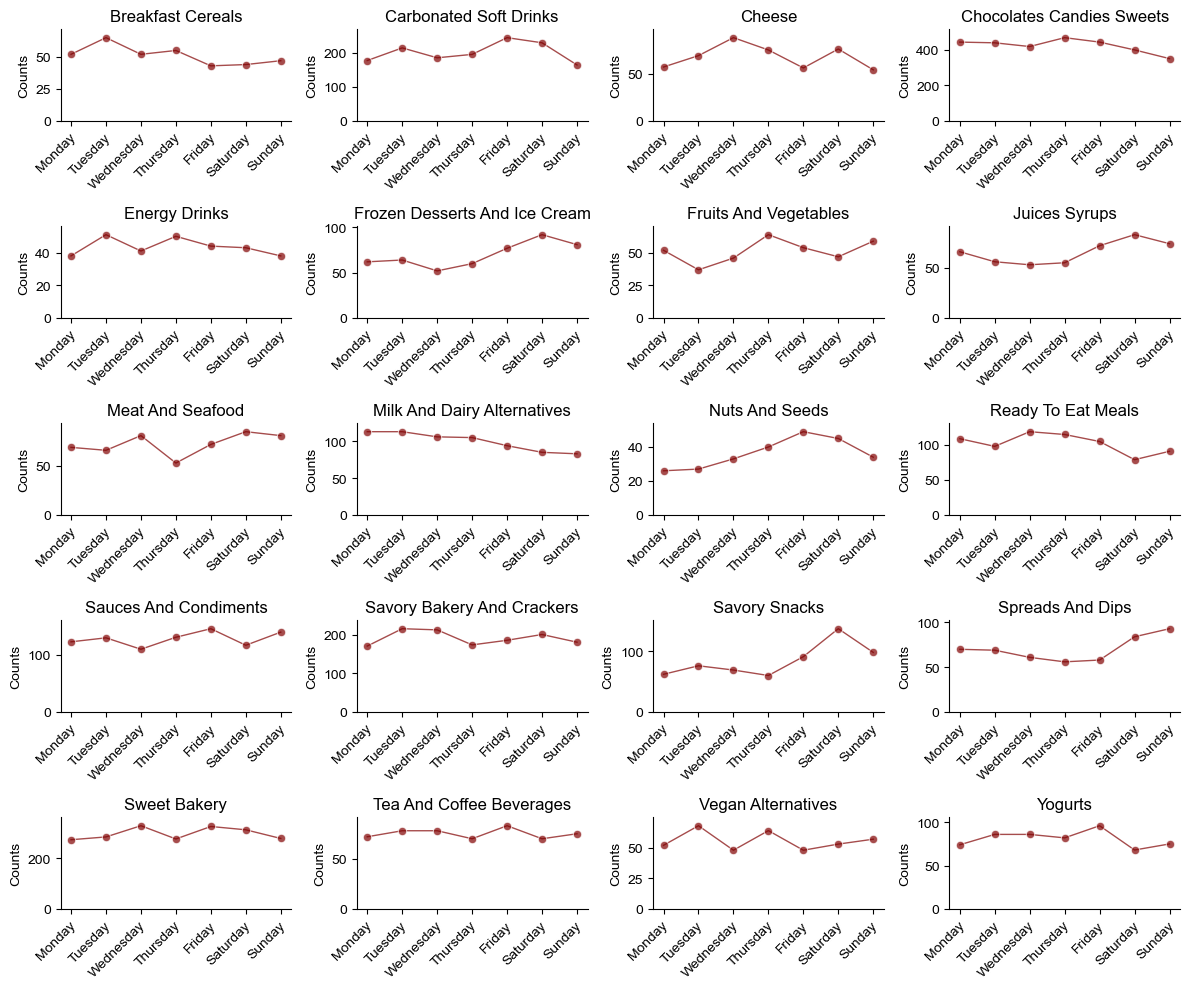

In [38]:
ncols, nrows = 4, 5
fig, ax = plt.subplots(
    ncols=ncols,
    nrows=nrows,
    figsize=(ncols * 3, nrows * 2),
)

print("Showing only the first", ncols * nrows, "food groups")

for i, fc in enumerate(
    sorted(additive_foods["food_group"].value_counts().index[: ncols * nrows])
):
    r, c = i // ncols, i % ncols  # Calculate row and column indices
    plot_food_group_week_trend(
        fc, plot_pivot_df, ax[r, c], color="maroon", ylim_bottom=0
    )

sns.despine()
plt.tight_layout()

plt.savefig(
    "../figures/additive_descriptive/food_group_weekly_consumption_trends_all.png",
    dpi=300,
    bbox_inches="tight",
)

## Plot Weekly Consumption Merged format

In [39]:
def _prep_week_series(plot_pivot_df, foods, normalize=None, week_order=None):
    """
    normalize:
      None            keep counts
      "row"           each food scaled to sum=1 across week
      "max"           each food scaled to max=1
      "z"             z-score per food across week
    """
    if week_order is None:
        week_order = [
            "Monday",
            "Tuesday",
            "Wednesday",
            "Thursday",
            "Friday",
            "Saturday",
            "Sunday",
        ]

    df = plot_pivot_df.loc[foods, week_order].copy()

    if normalize is None:
        return df
    if normalize == "row":
        return df.div(df.sum(axis=1).replace(0, float("nan")), axis=0)
    if normalize == "max":
        return df.div(df.max(axis=1).replace(0, float("nan")), axis=0)
    if normalize == "z":
        return df.sub(df.mean(axis=1), axis=0).div(
            df.std(axis=1).replace(0, float("nan")), axis=0
        )

    raise ValueError("normalize must be one of: None, 'row', 'max', 'z'")

In [40]:
def plot_weekly_highlight_one(
    plot_pivot_df,
    foods,
    highlight,
    normalize=None,
    *,
    title=None,
    fig_size=(7.5, 4.2),
    linewidth=2.2,
    faint_alpha=0.25,
    show_markers=True,
    bbox_to_anchor=(1.02, 1.0),
    legend_ncol=1,
):
    """
    Spaghetti plot where all food groups keep their identity (color + full legend),
    while one or more selected food groups are emphasized with higher alpha and thicker line.

    highlight: str or iterable[str]
    """
    df = _prep_week_series(plot_pivot_df, foods, normalize=normalize)
    df.index = df.index.map(process_string)

    # allow single highlight or multiple
    if highlight is None:
        highlight_set = set()
    elif isinstance(highlight, (list, tuple, set)):
        highlight_set = {process_string(h) for h in highlight}
    else:
        highlight_set = {process_string(highlight)}

    ax = plt.figure(figsize=fig_size).add_subplot(111)

    colors = plt.cm.tab10_r.colors
    color_map = {food: colors[i % len(colors)] for i, food in enumerate(df.index)}

    for food in df.index:
        y = df.loc[food].values
        is_hi = food in highlight_set

        ax.plot(
            df.columns,
            y,
            color=color_map[food],
            marker="o" if show_markers else None,
            linewidth=linewidth if is_hi else linewidth * 0.9,
            alpha=1.0 if is_hi else faint_alpha,
            label=str(food),
        )

    if title:
        ax.set_title(title)

    ax.set_ylabel(
        "Count"
        if normalize is None
        else (
            "Share of weekly presence"
            if normalize == "row"
            else "Scaled to max=1" if normalize == "max" else "Z-score"
        )
    )

    plt.setp(
        ax.get_xticklabels(), rotation=30, ha="right", rotation_mode="anchor", va="top"
    )

    ax.yaxis.grid(True, linestyle=":", linewidth=0.8, alpha=0.6)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    handles, labels = ax.get_legend_handles_labels()
    leg = ax.legend(
        handles,
        labels,
        frameon=False,
        # loc="upper left",
        bbox_to_anchor=bbox_to_anchor,
        ncol=legend_ncol,
    )

    for text in leg.get_texts():
        if text.get_text() in highlight_set:
            text.set_fontweight("bold")
            text.set_alpha(1.0)
        else:
            text.set_alpha(0.6)

    return ax

In [41]:
def weekly_weekend_contrast(
    plot_pivot_df,
    weekend_days=("Saturday", "Sunday"),
    weekday_days=("Monday", "Tuesday", "Wednesday", "Thursday", "Friday"),
):
    weekend = plot_pivot_df[list(weekend_days)].mean(axis=1)
    weekday = plot_pivot_df[list(weekday_days)].mean(axis=1)
    return (weekend - weekday).abs()


def weekly_range(plot_pivot_df):
    return plot_pivot_df.max(axis=1) - plot_pivot_df.min(axis=1)


def weekly_cv(plot_pivot_df):
    mean = plot_pivot_df.mean(axis=1)
    std = plot_pivot_df.std(axis=1)
    return std / mean.replace(0, float("nan"))


def select_most_variable_foods(
    plot_pivot_df,
    n=8,
    method="cv",
    min_total=0,
):
    df = plot_pivot_df.copy()

    if min_total > 0:
        df = df.loc[df.sum(axis=1) >= min_total]

    if method == "cv":
        score = weekly_cv(df)
    elif method == "range":
        score = weekly_range(df)
    elif method == "weekend_contrast":
        score = weekly_weekend_contrast(df)
    else:
        raise ValueError("method must be 'cv', 'range', or 'weekend_contrast'")

    return score.sort_values(ascending=False).head(n).index.tolist()

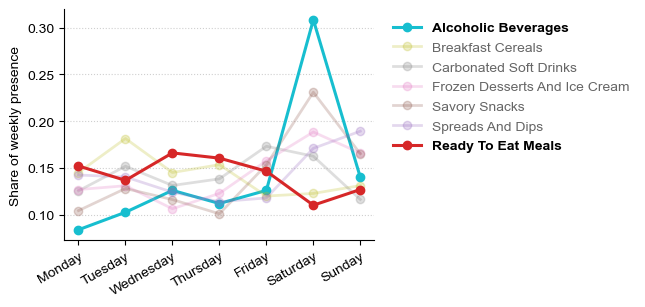

In [42]:
selected_foods = select_most_variable_foods(
    plot_pivot_df,
    n=6,
    method="weekend_contrast",
    min_total=50,
)

ax = plot_weekly_highlight_one(
    plot_pivot_df,
    foods=[
        "alcoholic_beverages",
        "breakfast_cereals",
        "carbonated_soft_drinks",
        "frozen_desserts_and_ice_cream",
        "savory_snacks",
        "spreads_and_dips",
        "ready_to_eat_meals",
    ],
    highlight=["ready_to_eat_meals", "alcoholic_beverages"],
    normalize="row",
    title=None,
    fig_size=(4, 3.0),
    faint_alpha=0.25,
    # bbox_to_anchor=(-0.16, 0.8),
    # legend_ncol=1,
)

plt.savefig(
    "../figures/additive_descriptive/food_group_weekly_consumption_trends_highlighted.png",
    dpi=300,
    bbox_inches="tight",
)

## Stacked bar plot for weekday vs weekend ratio of food group consumptions

In [43]:
def prepare_weekday_weekend_stacked(
    plot_pivot_df,
    foods=None,
    weekend_days=("Saturday", "Sunday"),
    weekday_days=("Monday", "Tuesday", "Wednesday", "Thursday", "Friday"),
    min_total=0,
    normalize="row",  # "row" or None
    sort_by="weekend_prop",
    descending=True,
):
    df = plot_pivot_df.copy()

    if foods is not None:
        df = df.loc[foods]

    weekday = df[list(weekday_days)].sum(axis=1)
    weekend = df[list(weekend_days)].sum(axis=1)
    total = weekday + weekend

    out = df.assign(
        weekday=weekday,
        weekend=weekend,
        total=total,
        weekend_prop=weekend / total.replace(0, float("nan")),
    )

    out = out.loc[out["total"] >= min_total]

    if normalize == "row":
        out["weekday"] = out["weekday"] / out["total"]
        out["weekend"] = out["weekend"] / out["total"]

    if sort_by is not None:
        out = out.sort_values(sort_by, ascending=not descending)

    return out[["weekday", "weekend", "total", "weekend_prop"]]

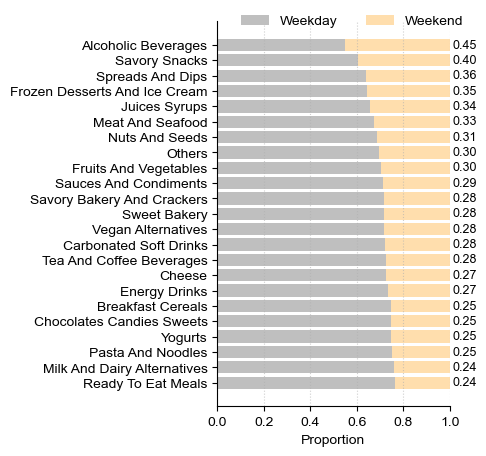

In [44]:
def plot_weekday_weekend_stacked_barh(
    plot_pivot_df,
    foods=None,
    top_n=25,
    min_total=0,
    normalize="row",
    title=None,
    figsize=(5, 5.0),
    colors=("0.75", "0.25"),
    annotate=True,
):
    t = prepare_weekday_weekend_stacked(
        plot_pivot_df,
        foods=foods,
        min_total=min_total,
        normalize=normalize,
    ).head(top_n)

    fig = plt.figure(figsize=figsize)
    ax = fig.add_subplot(111)

    y = range(len(t.index))

    ax.barh(y, t["weekday"], color=colors[0], label="Weekday")
    ax.barh(y, t["weekend"], left=t["weekday"], color=colors[1], label="Weekend")

    # Apply process_string to yticklabels
    processed_labels = [process_string(label) for label in t.index]
    ax.set_yticks(list(y))
    ax.set_yticklabels(processed_labels)
    ax.invert_yaxis()

    ax.set_xlim(0, 1 if normalize == "row" else None)
    ax.set_xlabel("Proportion" if normalize == "row" else "Count")
    if title:
        ax.set_title(title)

    # Move legend outside to the right
    ax.legend(frameon=False, loc="center left", bbox_to_anchor=(0.05, 1), ncol=2)

    ax.xaxis.grid(True, linestyle=":", linewidth=0.8, alpha=0.6)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    if annotate and normalize == "row":
        for i, wp in enumerate(t["weekend"]):
            ax.text(
                t["weekday"].iloc[i] + wp + 0.01,
                i,
                f"{wp:.2f}",
                va="center",
                fontsize=9,
            )

    return ax


plot_weekday_weekend_stacked_barh(
    plot_pivot_df,
    colors=("0.75", "navajowhite"),
    figsize=(3, 5.0),
    title=None,
)

plt.savefig(
    "../figures/additive_descriptive/food_group_weekday_weekend_stacked_barh.png",
    dpi=300,
    bbox_inches="tight",
)